# KHAI PHÁ DỮ LIỆU — LAB 1 · Phần 1 · Bài 2 (Trang 28): Khảo sát và tiền xử lý dữ liệu Bank Marketing

            | | |
            |---|---|
            | **Sinh viên** | Phan Quốc Thắng |
            | **MSSV** | 6451071073 |
            | **Lớp** | CNTT-K64 |
            | **GVHD** | ThS. Nguyễn Thiện Dương |

            **Dữ liệu:** `data/bank/bank-full.csv` (UCI Bank Marketing — Moro et al., 2014; 45 211 khách hàng, 17 thuộc tính,
phân cách `;`). Thuộc tính quyết định: `y` — khách hàng có đăng ký gửi tiền có kỳ hạn hay không.

Thực hiện lại đúng 8 bước của phần hướng dẫn (Titanic) trên dữ liệu Bank Marketing.
Trong dữ liệu này giá trị thiếu được ghi bằng chuỗi `"unknown"`.

## Khai báo thông tin sinh viên & thư viện

In [1]:
HO_TEN = "Phan Quốc Thắng"
MSSV = "6451071073"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
SEED = int(MSSV[-4:])          # seed lấy từ MSSV để kết quả tái lập được
rng = np.random.default_rng(SEED)
DATA = "../data/"

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


## Câu 1: Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính

In [2]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df = pd.read_csv(DATA + "bank/bank-full.csv", sep=";")
print("Kích thước dữ liệu (dòng, cột):", df.shape)
display(df.head())
df.info()
print("\nThống kê các thuộc tính định lượng:")
display(df.describe().round(2))
print("Thống kê các thuộc tính định tính:")
display(df.describe(include="object"))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Kích thước dữ liệu (dòng, cột): (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB

Thống kê các thuộc tính định lượng:


,age,balance,day,duration,campaign,pdays,previous
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,258.16,2.76,40.20,0.58
std,10.62,3044.77,8.32,257.53,3.10,100.13,2.30
min,18.00,-8019.00,1.00,0.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00


Thống kê các thuộc tính định tính:


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


**Nhận xét:**

- Dữ liệu có **45 211 khách hàng × 17 thuộc tính**: 7 thuộc tính số (`age, balance, day, duration, campaign, pdays, previous`) và 10 thuộc tính định tính.
- Lớp quyết định **mất cân bằng**: `y = no` chiếm 39 922/45 211 = 88.3%, chỉ 11.7% khách đăng ký. Vì vậy khi đánh giá mô hình không nên chỉ dùng accuracy.
- `balance` dao động rất rộng (−8 019 → 102 127, trung vị 448), `duration` từ 0 đến 4 918 giây (trung vị 180). Cả hai lệch phải mạnh.
- `pdays = −1` ở hơn 75% số dòng, nghĩa là phần lớn khách chưa từng được liên hệ ở chiến dịch trước. `info()` báo không có giá trị rỗng, nhưng giá trị thiếu thực chất được ghi là chuỗi `"unknown"`.

## Câu 2: Liệt kê 5 thuộc tính có số lượng giá trị rỗng (unknown) nhiều nhất

In [3]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
print("Số giá trị NaN thực sự trong file:", int(df.isnull().sum().sum()))
df = df.replace("unknown", np.nan)          # 'unknown' chính là giá trị thiếu
so_rong = df.isnull().sum().sort_values(ascending=False)
top5 = pd.DataFrame({"So_gia_tri_rong": so_rong,
                     "Ty_le_(%)": (so_rong / len(df) * 100).round(2)}).head(5)
display(top5)

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Số giá trị NaN thực sự trong file: 0


,So_gia_tri_rong,Ty_le_(%)
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
age,0,0.00


**Nhận xét:**

- Sau khi đổi `"unknown"` thành NaN, 5 thuộc tính thiếu nhiều nhất là `poutcome` (81.75%), `contact` (28.80%), `education` (4.11%), `job` (0.64%) và `age` (0%). Như vậy thực tế chỉ có 4 thuộc tính bị thiếu.
- `poutcome` thiếu quá nhiều nên khó điền một cách tin cậy. `job` và `education` thiếu ít, có thể điền bằng mode.

## Câu 3: Biểu đồ khảo sát sự liên quan giữa Độ tuổi (age), Tình trạng hôn nhân (marital) và khả năng đăng ký (y)

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


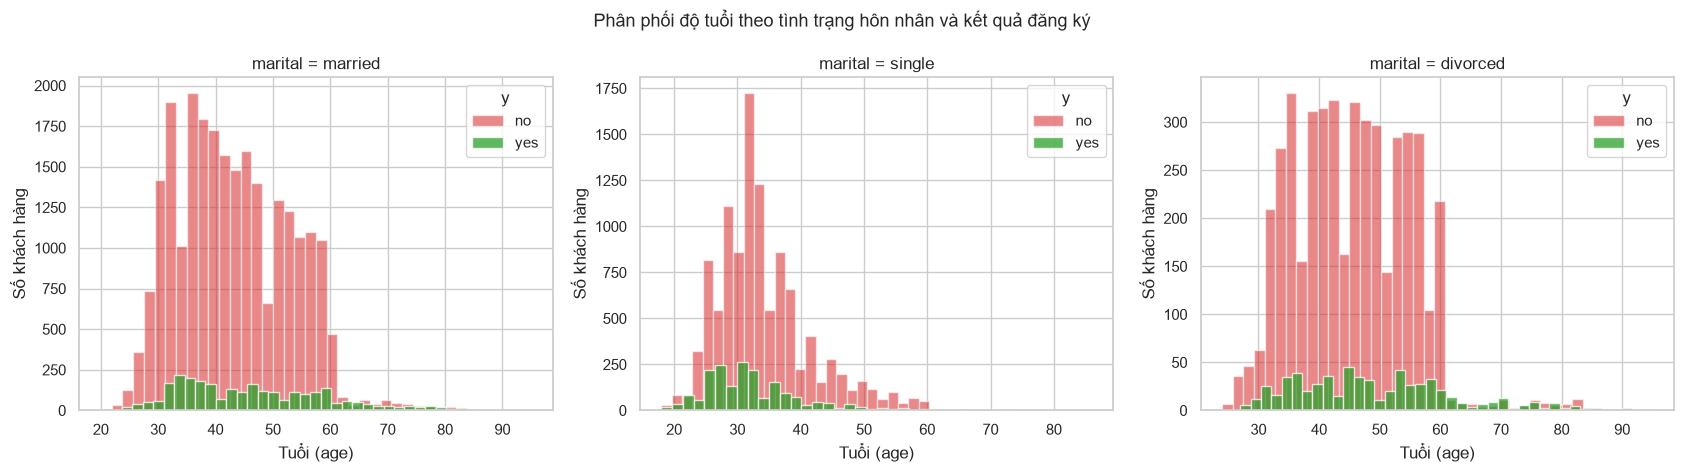

Tỷ lệ đăng ký (%) theo nhóm tuổi và tình trạng hôn nhân:


marital,divorced,married,single
nhom_tuoi,,,
"(17, 25]",0.0,14.4,25.7
"(25, 30]",11.0,8.3,17.8
"(30, 40]",10.2,9.2,12.1
"(40, 50]",10.0,8.3,12.3
"(50, 60]",11.3,9.7,10.7
"(60, 95]",48.7,41.5,26.5


In [4]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df["y_num"] = (df["y"] == "yes").astype(int)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, m in zip(axes, ["married", "single", "divorced"]):
    d = df[df["marital"] == m]
    ax.hist(d.loc[d["y"] == "no", "age"], bins=40, alpha=0.55, color="tab:red", label="no")
    ax.hist(d.loc[d["y"] == "yes", "age"], bins=40, alpha=0.75, color="tab:green", label="yes")
    ax.set_title(f"marital = {m}"); ax.set_xlabel("Tuổi (age)"); ax.set_ylabel("Số khách hàng"); ax.legend(title="y")
plt.suptitle("Phân phối độ tuổi theo tình trạng hôn nhân và kết quả đăng ký", fontsize=13)
plt.tight_layout(); plt.show()

tmp = df.copy()
tmp["nhom_tuoi"] = pd.cut(tmp["age"], bins=[17, 25, 30, 40, 50, 60, 95])
bang = tmp.pivot_table(values="y_num", index="nhom_tuoi", columns="marital", aggfunc="mean", observed=False)
print("Tỷ lệ đăng ký (%) theo nhóm tuổi và tình trạng hôn nhân:")
display((bang * 100).round(1))

**Nhận xét:**

- Tỷ lệ đăng ký có dạng **chữ U theo tuổi**. Khách trên 60 tuổi đăng ký nhiều nhất (divorced 48.7%, married 41.5%, single 26.5%), khách trẻ 17 – 25 tuổi cũng cao (single 25.7%). Nhóm trung niên 30 – 60 chỉ đạt khoảng 8 – 12%.
- Ở hầu hết các nhóm tuổi dưới 50, người độc thân (`single`) đăng ký nhiều hơn người đã kết hôn.
- Histogram cho thấy phần lớn khách hàng ở độ tuổi 30 – 60 và đã kết hôn (27 214 người). Nhóm này đông nhưng tỷ lệ đăng ký thấp.

## Câu 4: Biểu đồ khảo sát Trình độ học vấn (education), Nghề nghiệp (job) với khả năng đăng ký, phân biệt theo marital

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


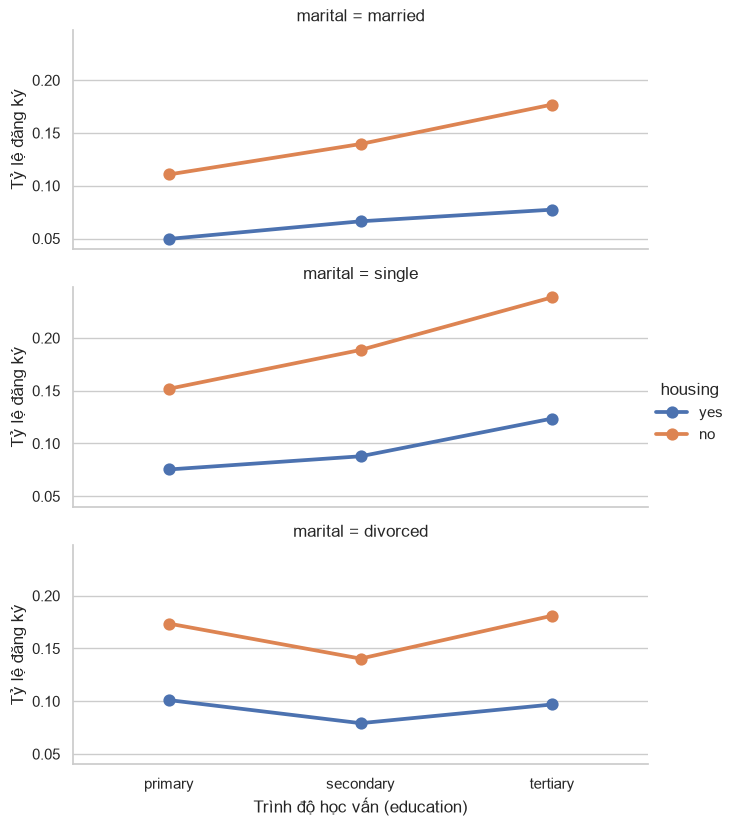

Tỷ lệ đăng ký (%) theo education và marital:


marital,divorced,married,single
education,,,
primary,13.8,7.5,10.7
secondary,10.3,9.5,12.9
tertiary,13.8,13.0,18.4


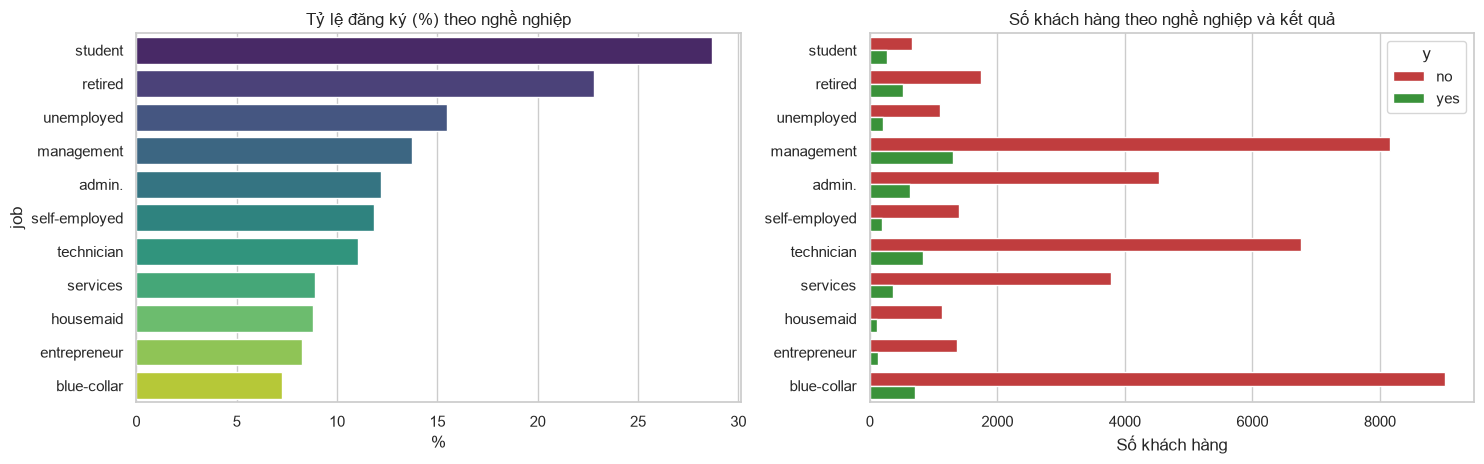

In [5]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
g = sns.FacetGrid(df.dropna(subset=["education"]), row="marital", row_order=["married", "single", "divorced"],
                  height=2.8, aspect=2.4)
g.map_dataframe(sns.pointplot, x="education", y="y_num", hue="housing", order=["primary", "secondary", "tertiary"],
                hue_order=["yes", "no"], palette="deep", errorbar=None)
g.add_legend(title="housing"); g.set_axis_labels("Trình độ học vấn (education)", "Tỷ lệ đăng ký")
plt.show()
print("Tỷ lệ đăng ký (%) theo education và marital:")
display((df.pivot_table(values="y_num", index="education", columns="marital") * 100).round(1))

job_rate = df.groupby("job")["y_num"].mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.barplot(x=job_rate.values * 100, y=job_rate.index, ax=axes[0], palette="viridis")
axes[0].set_title("Tỷ lệ đăng ký (%) theo nghề nghiệp"); axes[0].set_xlabel("%"); axes[0].set_ylabel("job")
sns.countplot(data=df, y="job", hue="y", order=job_rate.index, ax=axes[1], palette=["tab:red", "tab:green"])
axes[1].set_title("Số khách hàng theo nghề nghiệp và kết quả"); axes[1].set_xlabel("Số khách hàng"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Nhận xét:**

- Học vấn càng cao thì tỷ lệ đăng ký càng cao: `tertiary` đạt 13.0 – 18.4%, cao nhất ở người độc thân có trình độ đại học (18.4%). Thấp nhất là người đã kết hôn có trình độ tiểu học (7.5%).
- Ở mọi trình độ, người **không** vay mua nhà (`housing = no`) đăng ký nhiều gấp khoảng 2 lần người có vay, ví dụ với tertiary là 20.0% so với 9.6%.
- Theo nghề nghiệp, `student` (28.7%) và `retired` (22.8%) đăng ký nhiều nhất, còn `blue-collar` (7.3%), `entrepreneur` (8.3%), `housemaid` (8.8%) thấp nhất. Tuy nhiên `blue-collar` lại là nhóm đông nhất (9 732 người).

## Câu 5: Thống kê số khoản vay/nợ (default, housing, loan) và khảo sát sự liên quan với thuộc tính quyết định

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Số khách hàng không có khoản vay/nợ nào: 16992
Số khách hàng có ít nhất 1 khoản vay/nợ : 28219


,So_khach,Ty_le_dang_ky
n_loans,,
0,16992,18.36
1,23382,8.01
2,4704,6.12
3,133,5.26


Tỷ lệ đăng ký (%) theo default: {'no': 11.8, 'yes': 6.38}
Tỷ lệ đăng ký (%) theo housing: {'no': 16.7, 'yes': 7.7}
Tỷ lệ đăng ký (%) theo loan: {'no': 12.66, 'yes': 6.68}


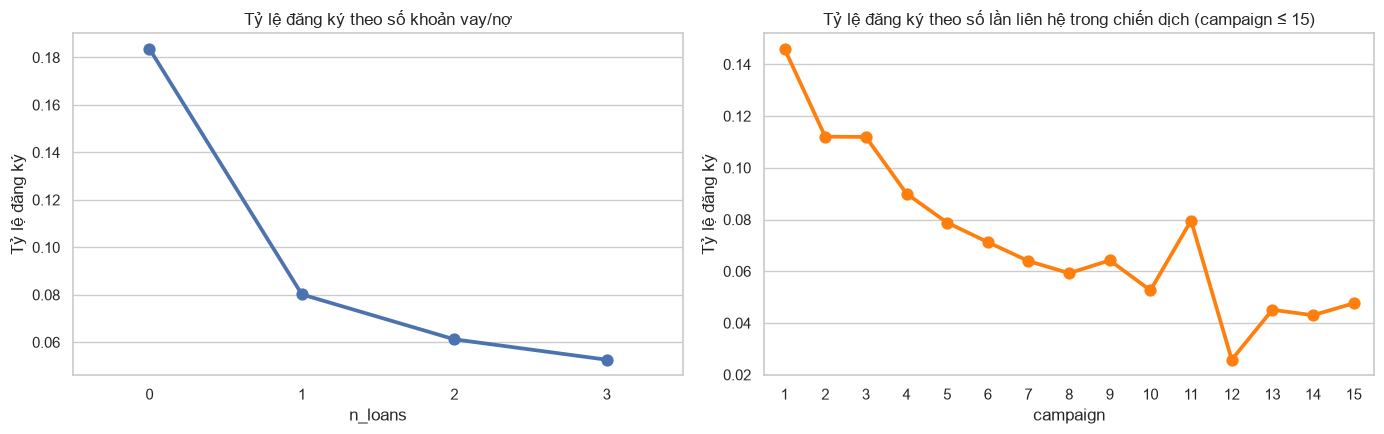

In [6]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
# Tương tự 'số người đi cùng' ở Titanic: đếm số khoản vay/nợ mà khách hàng đang có
df["n_loans"] = (df[["default", "housing", "loan"]] == "yes").sum(axis=1)
df["has_loan"] = (df["n_loans"] > 0).astype(int)
print("Số khách hàng không có khoản vay/nợ nào:", (df["has_loan"] == 0).sum())
print("Số khách hàng có ít nhất 1 khoản vay/nợ :", (df["has_loan"] == 1).sum())

thongke = df.groupby("n_loans")["y_num"].agg(So_khach="count", Ty_le_dang_ky="mean")
thongke["Ty_le_dang_ky"] = (thongke["Ty_le_dang_ky"] * 100).round(2)
display(thongke)
for c in ["default", "housing", "loan"]:
    print(f"Tỷ lệ đăng ký (%) theo {c}:", (df.groupby(c)["y_num"].mean() * 100).round(2).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.pointplot(data=df, x="n_loans", y="y_num", errorbar=None, ax=axes[0])
axes[0].set_title("Tỷ lệ đăng ký theo số khoản vay/nợ"); axes[0].set_xlabel("n_loans"); axes[0].set_ylabel("Tỷ lệ đăng ký")
sns.pointplot(data=df[df["campaign"] <= 15], x="campaign", y="y_num", errorbar=None, ax=axes[1], color="tab:orange")
axes[1].set_title("Tỷ lệ đăng ký theo số lần liên hệ trong chiến dịch (campaign ≤ 15)")
axes[1].set_xlabel("campaign"); axes[1].set_ylabel("Tỷ lệ đăng ký")
plt.tight_layout(); plt.show()

**Nhận xét:**

- 16 992 khách không có khoản vay/nợ nào và 28 219 khách có ít nhất một khoản.
- Tỷ lệ đăng ký giảm rõ khi số khoản nợ tăng: 18.36% (0 khoản) → 8.01% (1) → 6.12% (2) → 5.26% (3). Từng khoản riêng lẻ đều làm giảm tỷ lệ: housing 7.7% so với 16.7%, loan 6.68% so với 12.66%, default 6.38% so với 11.8%.
- Khách được gọi càng nhiều lần (`campaign`) thì tỷ lệ đăng ký càng giảm: 14.6% ở lần đầu, chỉ khoảng 2 – 8% khi bị gọi trên 10 lần. Ngân hàng nên ưu tiên khách không có nợ và tránh gọi lặp lại quá nhiều.

## Câu 6: Tiền xử lý các thuộc tính thiếu dữ liệu và xoá bỏ các thuộc tính không cần thiết

In [7]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
print("Tỷ lệ thiếu (%) trước xử lý:"); print((df.isnull().mean() * 100).round(2)[lambda s: s > 0].to_dict())
print("Giá trị poutcome:", df["poutcome"].value_counts(dropna=False).to_dict())
print("Giá trị contact :", df["contact"].value_counts(dropna=False).to_dict())

# poutcome thiếu 81.7%, contact (kênh liên lạc) thiếu 28.8% và ít ý nghĩa -> xoá; day (ngày trong tháng) không mang thông tin -> xoá
df = df.drop(columns=["poutcome", "contact", "day"])

# job, education (định tính, thiếu < 5%) -> điền giá trị xuất hiện nhiều nhất (mode) trong cùng lớp y
for c in ["job", "education"]:
    df[c] = df.groupby("y")[c].transform(lambda s: s.fillna(s.mode()[0]))
    print(f"Đã điền {c} theo mode của từng lớp y:", df.groupby("y")[c].agg(lambda s: s.mode()[0]).to_dict())

print("\nSố giá trị rỗng sau khi xử lý:")
display(df.isnull().sum().to_frame("So_gia_tri_rong").T)
print("Kích thước:", df.shape, "| Các thuộc tính:", list(df.columns))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Tỷ lệ thiếu (%) trước xử lý:
{'job': 0.64, 'education': 4.11, 'contact': 28.8, 'poutcome': 81.75}
Giá trị poutcome: {nan: 36959, 'failure': 4901, 'other': 1840, 'success': 1511}
Giá trị contact : {'cellular': 29285, nan: 13020, 'telephone': 2906}
Đã điền job theo mode của từng lớp y: {'no': 'blue-collar', 'yes': 'management'}
Đã điền education theo mode của từng lớp y: {'no': 'secondary', 'yes': 'secondary'}

Số giá trị rỗng sau khi xử lý:


,age,job,marital,education,default,balance,housing,loan,month,duration,campaign,pdays,previous,y,y_num,n_loans,has_loan
So_gia_tri_rong,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Kích thước: (45211, 17) | Các thuộc tính: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'month', 'duration', 'campaign', 'pdays', 'previous', 'y', 'y_num', 'n_loans', 'has_loan']


**Nhận xét:**

- `poutcome` (thiếu 81.75%), `contact` (thiếu 28.8%, chỉ là kênh liên lạc) và `day` (ngày trong tháng, không có ý nghĩa nhân quả) bị xoá.
- `job` và `education` được điền bằng **mode của từng lớp `y`**: với job, lớp `no` → blue-collar, lớp `yes` → management; với education, cả hai lớp đều là secondary.
- Lưu ý: điền theo lớp quyết định chỉ phù hợp cho mục đích khảo sát. Khi huấn luyện mô hình, phải tính mode trên tập train để tránh rò rỉ nhãn.
- Sau xử lý không còn giá trị rỗng. Dữ liệu có 17 cột, gồm cả các cột phụ `y_num, n_loans, has_loan` tạo ra để khảo sát.

## Câu 7: Biến đổi các thuộc tính (nhị phân, định tính, nhóm tuổi, nhóm số dư, nhóm thời lượng)

In [8]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
# (a) thuộc tính nhị phân yes/no -> 1/0
for c in ["default", "housing", "loan", "y"]:
    df[c] = df[c].map({"no": 0, "yes": 1})
# (b) marital -> số, education là thuộc tính thứ tự (ordinal) -> 1 < 2 < 3
df["marital"] = df["marital"].map({"single": 0, "married": 1, "divorced": 2})
df["education"] = df["education"].map({"primary": 1, "secondary": 2, "tertiary": 3})
# (c) month -> số tháng
df["month"] = df["month"].map({m: i for i, m in enumerate(
    ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], start=1)})
# (d) job là thuộc tính nominal 11 giá trị -> One-hot encoding để tránh quan hệ thứ bậc giả
df = pd.get_dummies(df, columns=["job"], prefix="job", dtype=int)
# (e) age -> 8 nhóm có số phần tử cân bằng (qcut)
df["age_group"], age_bins = pd.qcut(df["age"], 8, labels=range(1, 9), retbins=True)
df["age_group"] = df["age_group"].astype(int)
print("Ngưỡng 8 nhóm tuổi:", age_bins.round(1).tolist())
display(df["age_group"].value_counts().sort_index().to_frame("So_khach").T)
# (f) balance và duration -> 6 nhóm có số phần tử cân bằng
df["balance_group"], b_bins = pd.qcut(df["balance"], 6, labels=range(1, 7), retbins=True)
df["duration_group"], d_bins = pd.qcut(df["duration"], 6, labels=range(1, 7), retbins=True)
df[["balance_group", "duration_group"]] = df[["balance_group", "duration_group"]].astype(int)
print("Ngưỡng 6 nhóm balance :", b_bins.round(1).tolist())
print("Ngưỡng 6 nhóm duration:", d_bins.round(1).tolist())
df = df.drop(columns=["y_num"])
display(df.head())

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Ngưỡng 8 nhóm tuổi: [18.0, 30.0, 33.0, 36.0, 39.0, 43.0, 48.0, 55.0, 95.0]


age_group,1,2,3,4,5,6,7,8
So_khach,7030,6053,5630,4649,5049,5612,6288,4900


Ngưỡng 6 nhóm balance : [-8019.0, 2.0, 175.0, 448.0, 955.0, 2283.0, 102127.0]
Ngưỡng 6 nhóm duration: [0.0, 80.0, 126.0, 180.0, 258.0, 411.0, 4918.0]


,age,marital,education,default,balance,housing,loan,month,duration,campaign,pdays,previous,y,n_loans,has_loan,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,age_group,balance_group,duration_group
0,58,1,3,0,2143,1,0,5,261,1,-1,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,8,5,5
1,44,0,2,0,29,1,0,5,151,1,-1,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,6,2,3
2,33,1,2,0,2,1,1,5,76,1,-1,0,0,2,1,0,0,1,0,0,0,0,0,0,0,0,2,1,1
3,47,1,2,0,1506,1,0,5,92,1,-1,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,6,5,2
4,33,0,2,0,1,0,0,5,198,1,-1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,2,1,4


**Nhận xét:**

- Các thuộc tính nhị phân yes/no được chuyển thành 1/0. `education` có thứ tự tự nhiên nên mã hoá thành 1 < 2 < 3. `month` được chuyển thành số tháng.
- `job` là thuộc tính nominal có 11 giá trị, nên được mã hoá **One-hot** (11 cột `job_*`) để không tạo ra quan hệ thứ bậc giả như khi đánh số 1, 2, 3… (đúng như yêu cầu cơ bản 5).
- `age` được chia thành 8 nhóm bằng `qcut` (ngưỡng 18 / 30 / 33 / 36 / 39 / 43 / 48 / 55 / 95), mỗi nhóm có 4 649 – 7 030 khách. Các nhóm không bằng nhau tuyệt đối vì tuổi là số nguyên và có nhiều giá trị trùng.
- `balance` và `duration` mỗi thuộc tính được chia 6 nhóm có tần số gần bằng nhau. Cách này giúp giảm ảnh hưởng của các giá trị ngoại lai rất lớn.

## Câu 8: Tạo thuộc tính mới và chuẩn hoá Min-max

In [9]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df["age_education"] = df["age"] * df["education"]                         # tương tự age_class
df["duration_per_campaign"] = (df["duration"] / df["campaign"]).astype(int)  # thời lượng TB mỗi lần liên hệ
display(df[["age", "education", "age_education", "duration", "campaign", "duration_per_campaign"]].head(8))

# Chuẩn hoá Min-max các thuộc tính số về [0, 1] (yêu cầu cơ bản 6)
num_cols = ["age", "balance", "duration", "campaign", "pdays", "previous", "age_education", "duration_per_campaign"]
df_scaled = df.copy()
df_scaled[num_cols] = (df[num_cols] - df[num_cols].min()) / (df[num_cols].max() - df[num_cols].min())
print("Sau chuẩn hoá Min-max:")
display(df_scaled[num_cols].describe().loc[["min", "max", "mean"]].round(4))
print("Kích thước dữ liệu sau tiền xử lý:", df_scaled.shape)
display(df_scaled.head())

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


,age,education,age_education,duration,campaign,duration_per_campaign
0,58,3,174,261,1,261
1,44,2,88,151,1,151
2,33,2,66,76,1,76
3,47,2,94,92,1,92
4,33,2,66,198,1,198
5,35,3,105,139,1,139
6,28,3,84,217,1,217
7,42,3,126,380,1,380


Sau chuẩn hoá Min-max:


,age,balance,duration,campaign,pdays,previous,age_education,duration_per_campaign
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
max,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
mean,0.2979,0.0852,0.0525,0.0284,0.0472,0.0021,0.2754,0.0324


Kích thước dữ liệu sau tiền xử lý: (45211, 31)


,age,marital,education,default,balance,housing,loan,month,duration,campaign,pdays,previous,y,n_loans,has_loan,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,age_group,balance_group,duration_group,age_education,duration_per_campaign
0,0.519481,1,3,0,0.092259,1,0,5,0.053070,0.0,0.0,0.0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,8,5,5,0.626506,0.053070
1,0.337662,0,2,0,0.073067,1,0,5,0.030704,0.0,0.0,0.0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,6,2,3,0.281124,0.030704
2,0.194805,1,2,0,0.072822,1,1,5,0.015453,0.0,0.0,0.0,0,2,1,0,0,1,0,0,0,0,0,0,0,0,2,1,1,0.192771,0.015453
3,0.376623,1,2,0,0.086476,1,0,5,0.018707,0.0,0.0,0.0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,6,5,2,0.305221,0.018707
4,0.194805,0,2,0,0.072812,0,0,5,0.040260,0.0,0.0,0.0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,2,1,4,0.192771,0.040260


**Nhận xét:**

- `age_education = age × education` tương tự `age_class` của Titanic. `duration_per_campaign` là thời lượng trung bình của mỗi lần liên hệ, tương tự `fare_per_person`.
- Sau chuẩn hoá Min-max, mọi thuộc tính số nằm trong [0, 1]. Tuy vậy trung bình của `balance` (0.085), `duration` (0.053) và `previous` (0.002) rất gần 0, nghĩa là phần lớn dữ liệu bị nén sát 0 do ngoại lai. Với các cột lệch mạnh, nên log-transform hoặc dùng z-score/robust scaling trước khi đưa vào k-NN hay k-Means.
- Dữ liệu cuối cùng gồm **45 211 dòng × 31 thuộc tính, toàn bộ là số**.